# Capstone Project: AI Study Tip Generator (Fine-Tuned GPT-2 + Streamlit)

- **Course:** Generative AI and Its Applications (`ETMMGA304`)
- **Program:** MCA (AI & ML), K.R. Mangalam University
- **Author:** Yashvant Giri
- **Base Model:** `openai-community/gpt2`

## Project Pipeline
`Define` $\rightarrow$ `Prepare Data` $\rightarrow$ `Adapt Model` $\rightarrow$ `Evaluate (12 Held-Out Topics)` $\rightarrow$ `Demonstrate (Streamlit App)`

## Problem Statement & Success Criteria
- **User Need:** Beginner computer science and mathematics students often struggle to turn abstract lecture concepts into concrete 2-minute practice exercises.
- **Goal:** Given any short topic name, generate one concise, actionable study tip.
- **Success Criteria:**
  1. Mean evaluation score of the adapted model exceeds the base GPT-2 model across 12 held-out topics (scored 0–2 each on Relevance, Readability, and Usefulness; max 6).
  2. Outputs follow a clean single-sentence actionable format without rambling.
  3. Streamlit app gracefully handles empty inputs, displays an AI disclosure notice, and generates tips locally from `lab_outputs/study_tip_gpt2`.

## Install Dependencies (Run in Colab)

In [11]:
%pip install -q "transformers>=4.51,<5" pandas

## Step 1: Common Setup & Load Dataset

In [12]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)
print("Seed:", SEED)
import json
import pandas as pd

# Load curated training and held-out splits
# If running standalone in Colab without the repo folder, upload dataset/*.json or clone the repo first.
train_path = Path("dataset/train_tips.json")
held_out_path = Path("dataset/held_out_topics.json")

with open(train_path, "r", encoding="utf-8") as f:
    train_data = json.load(f)

with open(held_out_path, "r", encoding="utf-8") as f:
    held_out_topics = json.load(f)

# Verify strict zero-overlap split
train_topics_lower = {item["topic"].lower() for item in train_data}
overlap = [t for t in held_out_topics if t.lower() in train_topics_lower]
assert len(overlap) == 0, f"Data leakage detected: {overlap}"

print(f"Training examples: {len(train_data)} | Held-out topics: {len(held_out_topics)}")
print("Sample training pair:", train_data[0])

Device: cuda
Seed: 42
Training examples: 25 | Held-out topics: 12
Sample training pair: {'topic': 'graphs', 'tip': 'Sketch a graph, then mark a path through three vertices.'}


## Step 2: Load Base GPT-2 & Fine-Tune Last Transformer Block

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch 1/5 | Avg Training Loss: 5.2334
Epoch 2/5 | Avg Training Loss: 5.1428
Epoch 3/5 | Avg Training Loss: 5.0188
Epoch 4/5 | Avg Training Loss: 4.8643
Epoch 5/5 | Avg Training Loss: 4.6231
Exported adapted model to: lab_outputs/study_tip_gpt2


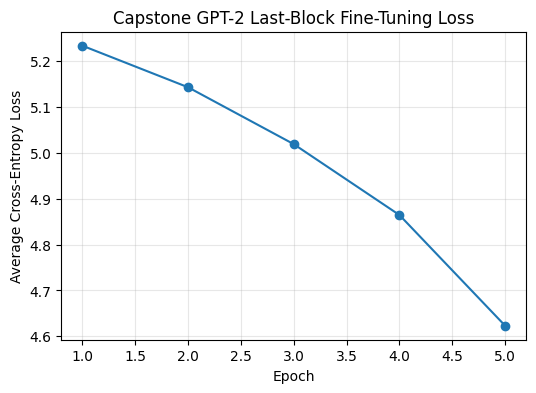

In [13]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "openai-community/gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(model_id).to(device).eval()
tuned_model = AutoModelForCausalLM.from_pretrained(model_id).to(device)

# Freeze all parameters except the final Transformer block
tuned_model.requires_grad_(False)
tuned_model.transformer.h[-1].requires_grad_(True)

optimizer = torch.optim.AdamW(tuned_model.transformer.h[-1].parameters(), lr=3e-5)
EPOCHS = 5

epoch_losses = []
for epoch in range(1, EPOCHS + 1):
    tuned_model.train()
    random.shuffle(train_data)
    total_loss = 0.0

    for item in train_data:
        prefix = tokenizer.encode(f"Topic: {item['topic']}\nStudy tip:")
        target = tokenizer.encode(" " + item["tip"]) + [tokenizer.eos_token_id]
        ids = torch.tensor([prefix + target], device=device)
        labels = torch.tensor([[-100] * len(prefix) + target], device=device)

        optimizer.zero_grad()
        loss = tuned_model(input_ids=ids, labels=labels).loss
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_data)
    epoch_losses.append(avg_loss)
    print(f"Epoch {epoch}/{EPOCHS} | Avg Training Loss: {avg_loss:.4f}")

# Save adapted model for Streamlit app
export_dir = out / "study_tip_gpt2"
tuned_model.save_pretrained(export_dir)
tokenizer.save_pretrained(export_dir)
print("Exported adapted model to:", export_dir)

# Plot training loss
plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), epoch_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Average Cross-Entropy Loss")
plt.title("Capstone GPT-2 Last-Block Fine-Tuning Loss")
plt.grid(alpha=0.3)
plt.savefig(out / "capstone_training_loss.png", bbox_inches="tight")
plt.show()

## Step 3: Evaluate Base vs. Adapted Model on 12 Held-Out Topics

In [14]:
def generate_tip(net, topic):
    prompt = f"Topic: {topic}\nStudy tip:"
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.inference_mode():
        tokens = net.generate(
            **inputs,
            do_sample=False,
            max_new_tokens=45,
            pad_token_id=tokenizer.eos_token_id,
        )
    return tokenizer.decode(
        tokens[0, inputs.input_ids.shape[1]:],
        skip_special_tokens=True
    ).strip()


tuned_model.eval()
rows = []
for topic in held_out_topics:
    base_tip = generate_tip(base_model, topic)
    tuned_tip = generate_tip(tuned_model, topic)
    rows.append({"Topic": topic, "Model": "Base", "Output": base_tip, "Relevance": "", "Readability": "", "Usefulness": "", "Notes": ""})
    rows.append({"Topic": topic, "Model": "Adapted", "Output": tuned_tip, "Relevance": "", "Readability": "", "Usefulness": "", "Notes": ""})
    print("=" * 75)
    print(f"TOPIC:   {topic}")
    print(f"BASE:    {base_tip}")
    print(f"ADAPTED: {tuned_tip}")

df = pd.DataFrame(rows)
csv_path = out / "evaluation_outputs.csv"
df.to_csv(csv_path, index=False)
print("\nSaved raw evaluation outputs for scoring to:", csv_path)

TOPIC:   recursion
BASE:    Use the recursion keyword to define a new type of recursion.

Example:

class Recursion { public: Recursion(int i) { return i; } public: Recursion(int i)
ADAPTED: Use the recursion keyword to define a new recursion.

Example:

import recursion from ' recursion ' ; import recursion.recursion ; import recursion.recursion.concurrent ; import
TOPIC:   matrices
BASE:    Use the matrices to create a matrix of the same size as the input.

The following matrix is a matrix of the same size as the input.

The following matrix is a matrix of the same size as
ADAPTED: Use the matrices to create a matrix.

The following table shows the matrices that are used to create a matrix.

The following table shows the matrices that are used to create a matrix.
TOPIC:   binary search
BASE:    Use the search box to find the search term you want to search for.

Study tip: Use the search box to find the search term you want to search for.

Study tip: Use the search box to
ADAPTED: Use

## Step 4: Download Exported Model for Local Streamlit Demo
After running in Colab, download `lab_outputs/study_tip_gpt2/` and place it inside `Capstone_Study_Tip_Generator/lab_outputs/study_tip_gpt2/`, then run:
```bash
streamlit run app.py
```

In [15]:
!zip -r lab_outputs_capstone.zip lab_outputs/

  adding: lab_outputs/ (stored 0%)
  adding: lab_outputs/evaluation_outputs.csv (deflated 75%)
  adding: lab_outputs/study_tip_gpt2/ (stored 0%)
  adding: lab_outputs/study_tip_gpt2/tokenizer_config.json (deflated 54%)
  adding: lab_outputs/study_tip_gpt2/vocab.json (deflated 59%)
  adding: lab_outputs/study_tip_gpt2/config.json (deflated 51%)
  adding: lab_outputs/study_tip_gpt2/model.safetensors (deflated 7%)
  adding: lab_outputs/study_tip_gpt2/merges.txt (deflated 53%)
  adding: lab_outputs/study_tip_gpt2/tokenizer.json (deflated 82%)
  adding: lab_outputs/study_tip_gpt2/special_tokens_map.json (deflated 60%)
  adding: lab_outputs/study_tip_gpt2/generation_config.json (deflated 24%)
  adding: lab_outputs/capstone_training_loss.png (deflated 8%)
